In [1]:
from dataclasses import dataclass
from functools import partial
from time import perf_counter

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Лабораторная работа 1

Функция из задачи 1, задание 5: тяжелый шарик и метод Нестерова

## 1. Свойства функции

### 1.1. Градиент и гессиан

Рассматриваем задачу

$$f(x)=\frac12\|Ax-b\|_2^2+\frac\alpha2\|x-a\|_2^2\to\min_x,$$

где $A\in\mathbb R^{m\times n}$, $a,x\in\mathbb R^n$,
$b\in\mathbb R^m$, $\alpha\ge0$. Раскроем квадраты:

$$f(x)=\frac12x^\top A^\top Ax-b^\top Ax+\frac12b^\top b
+\frac\alpha2x^\top x-\alpha a^\top x+\frac\alpha2a^\top a.$$

Матрица $B=A^\top A$ симметрична. Поэтому при дифференцировании
квадратичного слагаемого получаем

$$\frac{\partial}{\partial x_k}\left(\frac12x^\top Bx\right)
=\frac12\sum_j B_{kj}x_j+\frac12\sum_i B_{ik}x_i=(Bx)_k.$$

Производная $-b^\top Ax$ равна $-A^\top b$, а слагаемые без $x$
дают ноль. Аналогично дифференцируем вторую часть функции:

$$\nabla f(x)=A^\top(Ax-b)+\alpha(x-a),\qquad
\nabla^2f(x)=A^\top A+\alpha I_n.$$

Далее используем обозначения
$H=A^\top A+\alpha I_n$ и $q=A^\top b+\alpha a$.
Тогда $\nabla f(x)=Hx-q$.

### 1.2. Выпуклость

Для дифференцируемой выпуклой функции должно выполняться

$$f(y)\ge f(x)+\langle\nabla f(x),y-x\rangle.$$

Проверим это для нашей функции. Обозначим $d=y-x$. Поскольку функция
квадратичная, разложение по $d$ точное:

$$f(y)=f(x)+\langle\nabla f(x),d\rangle+\frac12d^\top Hd.$$

Последнее слагаемое неотрицательно:

$$d^\top Hd=\|Ad\|_2^2+\alpha\|d\|_2^2\ge0.$$

Значит, функция выпукла при любом $\alpha\ge0$.

### 1.3. Липшицевость градиента

Ищем наименьшее $L$, для которого
$\|\nabla f(x)-\nabla f(y)\|_2\le L\|x-y\|_2$.
Так как $\nabla f(x)-\nabla f(y)=H(x-y)$, получаем

$$\|\nabla f(x)-\nabla f(y)\|_2\le\|H\|_2\|x-y\|_2.$$

У симметричной положительно полуопределенной матрицы спектральная норма
равна наибольшему собственному значению. Поэтому

$$L=\lambda_{\max}(H)
=\lambda_{\max}(A^\top A)+\alpha
=\sigma_{\max}(A)^2+\alpha,$$

где $\sigma_{\max}(A)$ - наибольшее сингулярное число $A$.

### 1.4. Сильная выпуклость

Для сильной выпуклости с константой $\mu>0$ нужно, чтобы

$$f(y)\ge f(x)+\langle\nabla f(x),y-x\rangle
+\frac\mu2\|y-x\|_2^2.$$

По разложению из пункта 1.2 это равносильно
$d^\top Hd\ge\mu\|d\|_2^2$ для любого $d$.
Разложим $d=\sum_i c_i u_i$ по ортонормированным собственным векторам $H$:

$$d^\top Hd=\sum_i\lambda_i c_i^2,\qquad \|d\|_2^2=\sum_i c_i^2.$$

Отсюда

$$\lambda_{\min}(H)\|d\|_2^2\le d^\top Hd
\le\lambda_{\max}(H)\|d\|_2^2.$$

Значит, наибольшая подходящая константа равна

$$\mu=\lambda_{\min}(H)=\lambda_{\min}(A^\top A)+\alpha\ge\alpha.$$

При $\alpha>0$ функция всегда сильно выпукла. При $\alpha=0$ это верно
только при $\operatorname{rank}A=n$: тогда $\ker A=\{0\}$ и
$\|Ad\|^2>0$ для $d\ne0$. Если $\operatorname{rank}A<n$, получаем $\mu=0$.

### 1.5. Условия оптимальности

У выпуклой дифференцируемой функции точка $x^*$ является минимумом
тогда и только тогда, когда $\nabla f(x^*)=0$. В нашей задаче это дает

$$A^\top(Ax^*-b)+\alpha(x^*-a)=0
\quad\Longleftrightarrow\quad Hx^*=q.$$

При $\mu>0$ матрица $H$ обратима, поэтому минимум единственный:
$x^*=H^{-1}q$.

При $\alpha=0$ получаем нормальные уравнения метода наименьших квадратов
$A^\top A x^*=A^\top b$. Решение существует, но при
$\operatorname{rank}A<n$ оно неединственное: к нему можно прибавить любой вектор из $\ker A$.

## 2. Тестовые задачи

### 2.1. Генерация данных

Для каждого $n\in\{10,20,\ldots,100\}$ берем $m=n/2$ и создаем
100 задач: по 50 при $\alpha=0$ и $\alpha=1$. Элементы $A$, $a$ и $b$
генерируем из стандартного нормального распределения; $A$ делим на $\sqrt m$,
чтобы ее масштаб меньше зависел от размерности.

Так как $m<n$, матрица $A^\top A$ имеет нулевые собственные значения,
поэтому $\mu=\alpha$. Получаем две группы: без сильной выпуклости и с $\mu=1$.

In [2]:
SEED = 42
DIMENSIONS = tuple(range(10, 101, 10))
EXAMPLES_PER_GROUP = 50
EPS = 1e-10  # Допуск проверки градиента в решении CVXPY

### 2.2. Поиск минимума

Находим $x^*$ с помощью CVXPY и решателя OSQP. Минимизируем исходную функцию,
а затем подставляем найденную точку в градиент. Допуски решателя равны
$10^{-12}$, допуск проверки градиента - $10^{-10}$.
При $\mu=0$ CVXPY возвращает одно из решений.

In [3]:
@dataclass
class Problem:
    A: np.ndarray
    a: np.ndarray
    b: np.ndarray
    alpha: float
    group: str


def objective(problem, x):
    residual = problem.A @ x - problem.b
    displacement = x - problem.a
    return float(
        0.5 * (residual @ residual)
        + 0.5 * problem.alpha * (displacement @ displacement)
    )


def gradient(problem, x):
    return problem.A.T @ (problem.A @ x - problem.b) + problem.alpha * (x - problem.a)


def spectral_constants(problem):
    m, n = problem.A.shape
    # Считаем L через сингулярные числа, не формируя A.T @ A
    singular_values = np.linalg.svd(problem.A, compute_uv=False)
    L = float(singular_values[0] ** 2 + problem.alpha)
    # При m < n у A.T @ A есть нулевые собственные значения
    lambda_min = 0.0 if m < n else float(singular_values[-1] ** 2)
    mu = lambda_min + problem.alpha
    return L, mu


def solve_problem(problem):
    x = cp.Variable(problem.A.shape[1])
    cost = (
        0.5 * cp.sum_squares(problem.A @ x - problem.b)
        + 0.5 * problem.alpha * cp.sum_squares(x - problem.a)
    )
    task = cp.Problem(cp.Minimize(cost))
    task.solve(solver=cp.OSQP, eps_abs=1e-12, eps_rel=1e-12)
    return x.value

### 2.3. Проверка условия оптимальности

Для каждой найденной точки считаем
$\|\nabla f(x^*)\|_2=\|A^\top(Ax^*-b)+\alpha(x^*-a)\|_2$.
Сравниваем эту норму с допуском $10^{-10}$.

In [4]:
rng = np.random.default_rng(SEED)
problems, solutions, rows = [], [], []

for n in DIMENSIONS:
    m = n // 2
    for alpha in (0.0, 1.0):
        group = f"alpha={alpha:g}"
        for sample in range(EXAMPLES_PER_GROUP):
            # Нормировка удерживает масштаб A близким в разных размерностях
            problem = Problem(
                A=rng.standard_normal((m, n)) / np.sqrt(m),
                a=rng.standard_normal(n),
                b=rng.standard_normal(m),
                alpha=alpha,
                group=group,
            )
            L, mu = spectral_constants(problem)
            x_star = solve_problem(problem)
            # Проверяем условие оптимальности независимо от решателя
            grad_norm = np.linalg.norm(gradient(problem, x_star))

            problems.append(problem)
            solutions.append(x_star)
            rows.append(
                {
                    "n": n,
                    "m": m,
                    "group": group,
                    "sample": sample + 1,
                    "alpha": alpha,
                    "L": L,
                    "mu": mu,
                    "kappa": L / mu if mu > 0 else np.nan,
                    "f_star": objective(problem, x_star),
                    "fit_residual": np.linalg.norm(problem.A @ x_star - problem.b),
                    "grad_norm": grad_norm,
                    "is_optimal": grad_norm <= EPS,
                }
            )

results = pd.DataFrame(rows)

print(f"Решено задач: {len(results)}")
print(f"Условие оптимальности выполнено: {results['is_optimal'].sum()}")

Решено задач: 1000
Условие оптимальности выполнено: 1000


Сгруппируем результаты по размерности: сколько задач решено,
в скольких выполнено условие оптимальности и какие получились $L$ и $\mu$.

In [5]:
summary_by_n = (
    results.groupby("n")
    .agg(
        examples=("n", "size"),
        is_optimal=("is_optimal", "sum"),
        max_grad_norm=("grad_norm", "max"),
        min_L=("L", "min"),
        max_L=("L", "max"),
        min_mu=("mu", "min"),
        max_mu=("mu", "max"),
    )
    .rename(
        columns={
            "examples": "Число задач",
            "is_optimal": "Проверок пройдено",
            "max_grad_norm": "Макс. норма градиента",
            "min_L": "Мин. L",
            "max_L": "Макс. L",
            "min_mu": "Мин. mu",
            "max_mu": "Макс. mu",
        }
    )
)

summary_by_n

,Число задач,Проверок пройдено,Макс. норма градиента,Мин. L,Макс. L,Мин. mu,Макс. mu
n,,,,,,,
10,100,100,1.729010e-15,2.401816,10.055468,0.0,1.0
20,100,100,2.248373e-15,3.463115,8.392240,0.0,1.0
30,100,100,3.462098e-15,4.057366,7.620945,0.0,1.0
40,100,100,2.927457e-15,4.411512,7.674370,0.0,1.0
50,100,100,7.530660e-15,4.497659,7.117780,0.0,1.0
60,100,100,4.075575e-15,4.880294,7.452257,0.0,1.0
70,100,100,4.856039e-15,4.866588,7.214433,0.0,1.0
80,100,100,5.282577e-15,4.947335,7.136008,0.0,1.0
90,100,100,8.057085e-15,4.951635,7.146821,0.0,1.0


Для каждой размерности решены все 100 задач. Условие оптимальности выполнено во всех найденных точках.

In [6]:
summary_by_group = (
    results.groupby("group", sort=False)
    .agg(
        examples=("n", "size"),
        min_mu=("mu", "min"),
        max_mu=("mu", "max"),
        max_kappa=("kappa", "max"),
        mean_f_star=("f_star", "mean"),
        max_fit_residual=("fit_residual", "max"),
        max_grad_norm=("grad_norm", "max"),
    )
    .rename(
        columns={
            "examples": "Число задач",
            "min_mu": "Мин. mu",
            "max_mu": "Макс. mu",
            "max_kappa": "Макс. κ",
            "mean_f_star": "Среднее f*",
            "max_fit_residual": "Макс. остаток Ax-b",
            "max_grad_norm": "Макс. норма градиента",
        }
    )
)
summary_by_group.index.name = "Группа"

summary_by_group

,Число задач,Мин. mu,Макс. mu,Макс. κ,Среднее f*,Макс. остаток Ax-b,Макс. норма градиента
Группа,,,,,,,
alpha=0,500,0.0,0.0,NaN,2.048868e-30,7.926676e-15,1.264786e-14
alpha=1,500,1.0,1.0,10.055468,1.407860e+01,5.745174e+00,6.239023e-15


При $\alpha=0$ имеем $\mu=0$ и $f^*\approx0$: у сгенерированных матриц
полный строчный ранг, поэтому система $Ax=b$ разрешима.

При $\alpha=1$ имеем $\mu=1$ и единственный минимум. Теперь функция учитывает
и невязку $Ax-b$, и расстояние до $a$, поэтому в минимуме равенство $Ax^*=b$
уже не обязательно. Ниже приведены три задачи с наибольшей нормой градиента в найденной точке.

In [7]:
worst_examples = results.nlargest(3, "grad_norm")[
    [
        "n",
        "m",
        "alpha",
        "sample",
        "L",
        "mu",
        "f_star",
        "fit_residual",
        "grad_norm",
    ]
].rename(
    columns={
        "sample": "Пример в группе",
        "f_star": "f*",
        "fit_residual": "Норма Ax-b",
        "grad_norm": "Норма градиента",
    }
)

worst_examples

,n,m,alpha,Пример в группе,L,mu,f*,Норма Ax-b,Норма градиента
940,100,50,0.0,41,5.588084,0.0,3.141609e-29,7.926676e-15,1.264786e-14
916,100,50,0.0,17,5.317253,0.0,2.496209e-29,7.065705e-15,1.198684e-14
902,100,50,0.0,3,5.661718,0.0,1.452163e-29,5.389180e-15,8.611867e-15


In [8]:
print(f"Максимальная норма градиента: {results['grad_norm'].max():.3e}")
print(f"Допуск: {EPS:.0e}")
print(f"Задач c единственным минимумом: {results['mu'].gt(0).sum()}")
print(f"Задач c неединственным минимумом: {results['mu'].eq(0).sum()}")

Максимальная норма градиента: 1.265e-14
Допуск: 1e-10
Задач c единственным минимумом: 500
Задач c неединственным минимумом: 500


Во всех 1000 задачах норма градиента меньше $10^{-10}$.
В 500 задачах минимум единственный, в остальных 500 - нет.

## 3. Начальные точки и методы

Для каждой задачи генерируем 100 начальных точек из стандартного нормального
распределения. Фиксируем seed и используем одни и те же старты для всех методов:
`initial_points[i][j]` - старт $j$ задачи `problems[i]`.
В `results.loc[i]` хранятся $f^*$, $L$ и $\mu$.

Все методы останавливаем при $f(x_k)-f^*\le\varepsilon$, где
$\varepsilon=0.01$. Точку, число итераций, время и данные для графиков
возвращаем в одном формате. Число итераций ограничиваем 10 000.

In [9]:
STARTS_PER_PROBLEM = 100
# Отдельный генератор дает одинаковые старты независимо от генерации задач
start_rng = np.random.default_rng(SEED + 1)
initial_points = [
    start_rng.standard_normal((STARTS_PER_PROBLEM, problem.A.shape[1]))
    for problem in problems
]

print(f"Число задач: {len(initial_points)}")
print(f"Всего начальных точек: {sum(len(points) for points in initial_points)}")


def reached_accuracy(value, f_star, eps=0.01):
    return value - f_star <= eps

Число задач: 1000
Всего начальных точек: 100000


### 3a. Метод тяжелого шарика

Начинаем с $x_{-1}=x_0$. К градиентному шагу добавляем часть предыдущего перемещения:

$$x_{k+1}=x_k-h\nabla f(x_k)+\beta(x_k-x_{k-1}).$$

При $\mu>0$ используем параметры Поляка для квадратичной функции:

$$h=\frac4{(\sqrt L+\sqrt\mu)^2},\qquad
\beta=\left(\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}\right)^2.$$

In [10]:
accuracy = 0.01


def polyak_parameters(L, mu):
    root_sum = np.sqrt(L) + np.sqrt(mu)
    step = 4 / root_sum**2
    beta = ((np.sqrt(L) - np.sqrt(mu)) / root_sum)**2
    return step, beta

При постоянном шаге $h$ и $\beta$ считаем один раз. При подборе шага
пересчитываем их по текущей оценке $M$ вместо $L$; сам подбор описан в пункте 4d.
Траекторию сохраняем только для графиков, чтобы она не влияла на замеры времени.

In [11]:
@dataclass
class MethodResult:
    x: np.ndarray
    iterations: int
    elapsed: float
    converged: bool
    trajectory: list
    errors: list
    # Для подбора шага храним суммы, а не полную историю всех проб
    total_checks: int = 0
    trial_L_sum: float = 0.0
    total_rounds: int = 0
    accepted_L_sum: float = 0.0


def run_heavy_ball(
    problem, x0, f_star, L, mu, eps=0.01, keep_history=False,
    max_iter=10000, parameters=polyak_parameters, adaptive=False
):
    start = perf_counter()
    x = x0.copy()
    previous = x  # x_{-1} = x_0, начальная скорость равна нулю
    value = objective(problem, x)
    converged = reached_accuracy(value, f_star, eps)
    iterations = 0
    # При замерах история отключена, для графиков сохраняем и стартовую точку
    trajectory = [x] if keep_history else []
    errors = [value - f_star] if keep_history else []
    M = L
    total_checks = total_rounds = 0
    accepted_L_sum = trial_L_sum = 0.0

    step, beta = parameters(L, mu)

    while not converged and iterations < max_iter:
        # У тяжелого шарика градиент вычисляется в текущей точке x
        grad = gradient(problem, x)
        displacement = x - previous
        if adaptive:
            candidate, value, M, count, step_L_sum, rounds = adaptive_heavy_ball_step(
                problem, x, value, grad, displacement, M, L, mu, parameters
            )
            # Принятое M учитываем один раз, отклоненные пробы входят в trial_L_sum
            total_rounds += rounds
            accepted_L_sum += M
            total_checks += count
            trial_L_sum += step_L_sum
        else:
            candidate = x - step * grad + beta * displacement
            value = objective(problem, candidate)

        # Сначала сохраняем старую точку, затем переходим к новой
        previous, x = x, candidate
        iterations += 1
        converged = reached_accuracy(value, f_star, eps)
        if keep_history:
            trajectory.append(x)
            errors.append(value - f_star)

    return MethodResult(
        x, iterations, perf_counter() - start, converged,
        trajectory, errors, total_checks, trial_L_sum,
        total_rounds, accepted_L_sum
    )

### 3b. Метод Нестерова

Здесь сначала сдвигаемся по инерции в точку $y_k$, а градиент считаем уже в ней:

$$y_k=x_k+\beta(x_k-x_{k-1}),\qquad x_{k+1}=y_k-h\nabla f(y_k).$$

Начальные точки те же: $x_{-1}=x_0$. При $\mu>0$ берем

$$h=\frac1L,\qquad \beta=\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}.$$

При $\mu=0$ оставляем $h=1/L$, а коэффициент инерции меняем с номером шага:
$\beta_k=k/(k+3)$.

In [12]:
def nesterov_parameters(L, mu):
    step = 1.0 / L
    if mu > 0:
        root_sum = np.sqrt(L) + np.sqrt(mu)
        beta = (np.sqrt(L) - np.sqrt(mu)) / root_sum
    else:
        beta = None  # При mu = 0 коэффициент вычисляем по номеру итерации
    return step, beta

In [13]:
def run_nesterov(
    problem, x0, f_star, L, mu, eps=0.01,
    keep_history=False, max_iter=10000, adaptive=False
):
    start = perf_counter()
    x = x0.copy()
    previous = x  # Та же начальная скорость, что у тяжелого шарика
    value = objective(problem, x)
    converged = reached_accuracy(value, f_star, eps)
    iterations = 0
    trajectory = [x] if keep_history else []
    errors = [value - f_star] if keep_history else []
    M = L
    total_checks = total_rounds = 0
    accepted_L_sum = trial_L_sum = 0.0

    step, beta = nesterov_parameters(L, mu)

    while not converged and iterations < max_iter:
        displacement = x - previous
        if adaptive:
            # При изменении M заново вычисляем коэффициент инерции, y и градиент
            candidate, value, M, count, step_L_sum, rounds = adaptive_nesterov_step(
                problem, x, value, displacement, M, L, mu, iterations=iterations
            )
            total_rounds += rounds
            accepted_L_sum += M
            total_checks += count
            trial_L_sum += step_L_sum
        else:
            cur_beta = beta if beta is not None else iterations / (iterations + 3.0)
            # В отличие от тяжелого шарика градиент берем в точке сдвига y
            y = x + cur_beta * displacement
            candidate = y - step * gradient(problem, y)
            value = objective(problem, candidate)

        previous, x = x, candidate
        iterations += 1
        converged = reached_accuracy(value, f_star, eps)
        if keep_history:
            trajectory.append(x)
            errors.append(value - f_star)

    return MethodResult(
        x, iterations, perf_counter() - start, converged,
        trajectory, errors, total_checks, trial_L_sum,
        total_rounds, accepted_L_sum,
    )

## 4. Эксперименты

### 4a. Траектория при $n=2$

Берем $A=(3,1)$, $b=1$, $a=(0,0)$, $\alpha=1$ и старт $(-2,2)$.
Строим траекторию тяжелого шарика с постоянным шагом. Линии уровня показывают
значения функции, маркеры - точки после отдельных шагов.

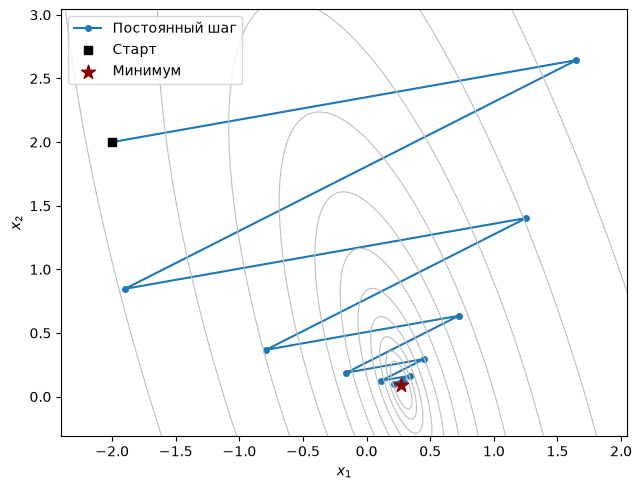

In [14]:
plane_problem = Problem(
    A=np.array([[3.0, 1.0]]), a=np.zeros(2), b=np.ones(1),
    alpha=1.0, group="alpha=1"
)
plane_start = np.array([-2.0, 2.0])
plane_minimum = solve_problem(plane_problem)
plane_value = objective(plane_problem, plane_minimum)
plane_L, plane_mu = spectral_constants(plane_problem)


def plot_trajectories(paths):
    fig, ax = plt.subplots(figsize=(7, 5))
    for label, path in paths.items():
        ax.plot(path[:, 0], path[:, 1], "o-", markersize=4, label=label)

    points = np.vstack([plane_minimum, *paths.values()])
    lower = points.min(axis=0) - 0.4
    upper = points.max(axis=0) + 0.4
    grid_x, grid_y = np.meshgrid(
        np.linspace(lower[0], upper[0], 180),
        np.linspace(lower[1], upper[1], 180)
    )
    # Значения на сетке нужны только для линий уровня
    residual = 3 * grid_x + grid_y - 1
    values = 0.5 * (residual**2 + grid_x**2 + grid_y**2)
    levels = plane_value + np.geomspace(0.02, values.max() - plane_value, 12)
    ax.contour(grid_x, grid_y, values, levels=levels, colors="0.75", linewidths=0.8)
    ax.scatter(*plane_start, marker="s", color="black", label="Старт", zorder=4)
    ax.scatter(*plane_minimum, marker="*", s=110, color="darkred", label="Минимум", zorder=4)
    ax.set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
    ax.legend()
    fig.tight_layout()
    plt.show()


plane_run = run_heavy_ball(
    plane_problem, plane_start, plane_value, plane_L, plane_mu, keep_history=True
)
paths = {"Постоянный шаг": np.array(plane_run.trajectory)}
plot_trajectories(paths)

Из точки $(-2,2)$ метод достиг точности $0.01$ за 11 итераций.

### 4b. Среднее время и число итераций

Сначала рассматриваем тяжелый шарик с постоянным шагом при $\mu=1$.
Для каждого $n$ усредняем результаты по 50 задачам и 100 стартам - всего
5000 запусков. Случай $\mu=0$ разобран в пункте 4g, общее сравнение - после пункта 4h.

Теория связывает число шагов с $\sqrt{L/\mu}$: чем больше этот множитель,
тем медленнее может сходиться метод. Поэтому добавим его среднее в таблицу.
Ниже отдельно сравним фактическое число шагов с верхними оценками для точности по функции.

In [15]:
fixed_label = "Тяжелый шарик"


def benchmark(indices, method, solver):
    rows = []
    for i in indices:
        problem = problems[i]
        row = results.loc[i]
        L, mu, f_star = row["L"], row["mu"], row["f_star"]
        # Каждый метод получает те же задачи, старты и точность
        for j, x0 in enumerate(initial_points[i]):
            # Время берем из метода, без подготовки данных и сохранения таблицы
            run = solver(problem, x0, f_star, L, mu, eps=accuracy)
            rows.append((
                i, j, problem.A.shape[1], L, mu, method, run.iterations, 1000 * run.elapsed,
                run.converged, run.total_checks, run.trial_L_sum,
                run.total_rounds, run.accepted_L_sum
            ))
    return pd.DataFrame.from_records(rows, columns=[
        "problem", "start", "n", "L", "mu", "method", "iterations", "time_ms",
        "converged", "checks", "trial_L_sum", "rounds", "accepted_L_sum"
    ])


strong_indices = results.index[results["mu"] > 0]
strong_runs = benchmark(strong_indices, fixed_label, run_heavy_ball)

,,iterations,time_ms,mean_sqrt_kappa
n,method,,,
10,Тяжелый шарик,6.074,0.047,2.362
20,Тяжелый шарик,6.597,0.052,2.435
30,Тяжелый шарик,6.946,0.056,2.485
40,Тяжелый шарик,7.197,0.057,2.519
50,Тяжелый шарик,7.235,0.059,2.497
60,Тяжелый шарик,7.412,0.061,2.527
70,Тяжелый шарик,7.502,0.063,2.524
80,Тяжелый шарик,7.671,0.067,2.545
90,Тяжелый шарик,7.775,0.070,2.547


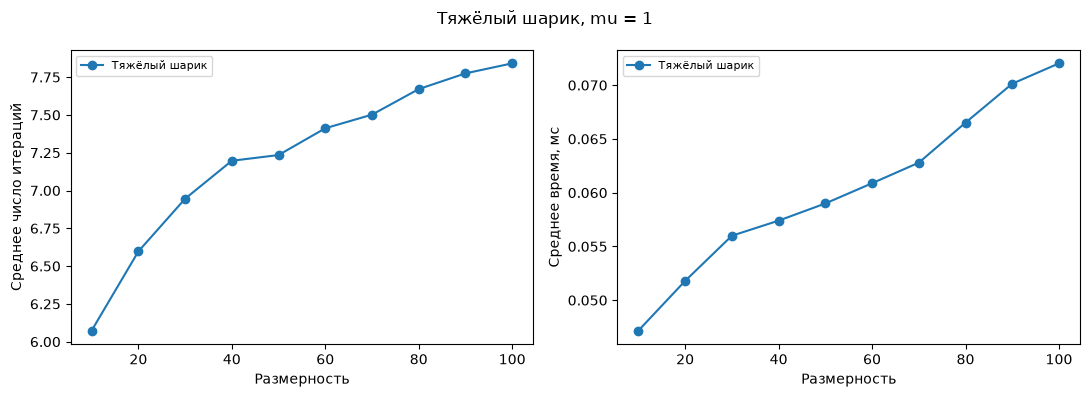

In [16]:
def summarize_by_n(runs):
    return runs.groupby(["n", "method"], sort=False).agg(
        iterations=("iterations", "mean"),
        time_ms=("time_ms", "mean")
    )


def plot_by_n(summary, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    fig.suptitle(title)
    for ax, column, ylabel in zip(
        axes, ("iterations", "time_ms"),
        ("Среднее число итераций", "Среднее время, мс")
    ):
        for method, data in summary.groupby(level="method", sort=False):
            series = data.droplevel("method")[column]
            ax.plot(series.index, series, "o-", label=method)
        ax.set(xlabel="Размерность", ylabel=ylabel)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


strong_problems = results.loc[strong_indices]
mean_sqrt_kappa = np.sqrt(strong_problems["kappa"]).groupby(strong_problems["n"]).mean()
fixed_by_n = summarize_by_n(strong_runs).join(mean_sqrt_kappa.rename("mean_sqrt_kappa"), on="n")
display(fixed_by_n.round(3))
plot_by_n(fixed_by_n, "Тяжелый шарик, mu = 1")

При росте $n$ от 10 до 100 среднее $\sqrt{L/\mu}$ выросло с 2,362 до 2,541,
а число итераций - с 6,074 до 7,841. Рост числа шагов согласуется с теорией,
но зависит также от начальной ошибки.

### 4c. Ошибка в зависимости от числа итераций

Берем первую задачу с $n=10$, $\alpha=1$ и первые три старта этой задачи.
Строим $f(x_k)-f^*$ в логарифмическом масштабе.

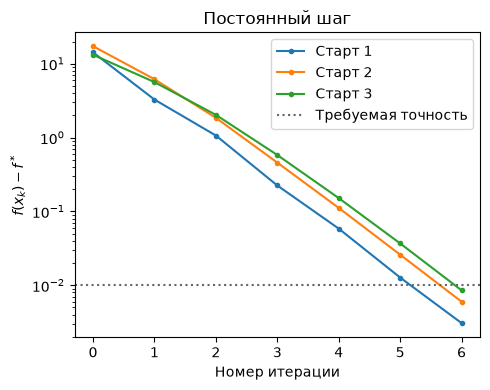

,Шаг,Старт,Итерации,Конечная ошибка,Точность достигнута,Проверки при подборе шага
0,Постоянный шаг,1,6,0.003072,True,0
1,Постоянный шаг,2,6,0.005990,True,0
2,Постоянный шаг,3,6,0.008535,True,0


In [17]:
example_index = results.index[(results["n"] == 10) & (results["alpha"] == 1)][0]
example = problems[example_index]
example_data = results.loc[example_index]
starts = initial_points[example_index][:3]


def example_runs(solver):
    return [
        solver(
            example, x0, example_data["f_star"], example_data["L"], example_data["mu"],
            eps=accuracy, keep_history=True
        )
        for x0 in starts
    ]


def plot_accuracy(samples):
    fig, axes = plt.subplots(
        1, len(samples), figsize=(5 * len(samples), 4),
        sharex=True, sharey=True, squeeze=False
    )
    rows = []
    for ax, (label, runs) in zip(axes[0], samples.items()):
        for number, run in enumerate(runs, start=1):
            # Логарифмический масштаб позволяет сравнить скорость уменьшения ошибки
            ax.semilogy(run.errors, "o-", markersize=3, label=f"Старт {number}")
            rows.append({
                "Шаг": label, "Старт": number, "Итерации": run.iterations,
                "Конечная ошибка": run.errors[-1], "Точность достигнута": run.converged,
                "Проверки при подборе шага": run.total_checks
            })
        ax.axhline(accuracy, color="0.4", linestyle=":", label="Требуемая точность")
        ax.set(title=label, xlabel="Номер итерации")
        ax.legend()
    axes[0, 0].set_ylabel("$f(x_k)-f^*$")
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame(rows))


samples = {"Постоянный шаг": example_runs(run_heavy_ball)}
plot_accuracy(samples)

На этой задаче из всех трех стартов точность достигнута за 6 итераций.

### 4d. Адаптивный подбор шага

#### Тяжелый шарик

Вместо $L$ используем пробную оценку $M$. Начинаем с $M=L/2$,
на следующих шагах делим предыдущую принятую оценку пополам.
Оставляем $M\ge\mu$ и $M>0$, чтобы параметры и деление на $M$ были определены.

Сначала пробуем шаг тяжелого шарика с параметрами для $M$. Принимаем точку $z$, если

$$f(z)\le f(x_k)-\frac{\|\nabla f(x_k)\|_2^2}{2M}.$$

Если условие не выполнено, пробуем обычный градиентный шаг
$z=x_k-\nabla f(x_k)/M$. Если не подошел и он, удваиваем $M$ и повторяем.
При $M\ge L$ градиентный шаг удовлетворяет условию по липшицевости градиента,
поэтому подбор заканчивается. Считаем все проверки пробных шагов, включая принятый.

In [18]:
def adaptive_heavy_ball_step(problem, x, value, grad, displacement, M, L, mu, parameters):
    # Пробуем увеличить шаг, сохраняя M >= mu и положительный знаменатель
    M = max(M / 2, mu, L * np.finfo(float).eps)
    grad_squared = grad @ grad
    checks = 0
    trial_L_sum = 0.0
    rounds = 0
    while True:
        rounds += 1
        step, beta = parameters(M, mu)
        threshold = value - grad_squared / (2 * M)
        # Сначала пробуем шаг с инерцией, затем обычный градиентный шаг
        for direction in (-step * grad + beta * displacement, -grad / M):
            candidate = x + direction
            candidate_value = objective(problem, candidate)
            checks += 1
            trial_L_sum += M
            if candidate_value <= threshold:
                return candidate, candidate_value, M, checks, trial_L_sum, rounds
        M *= 2  # Обе пробы отклонены, уменьшаем длину следующего шага


def adaptive_heavy_ball(problem, x0, f_star, L, mu, eps=0.01, keep_history=False):
    return run_heavy_ball(
        problem, x0, f_star, L, mu, eps=eps, keep_history=keep_history, adaptive=True
    )

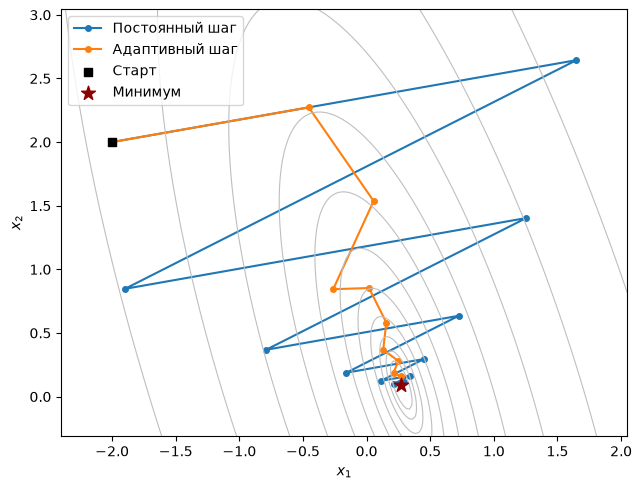

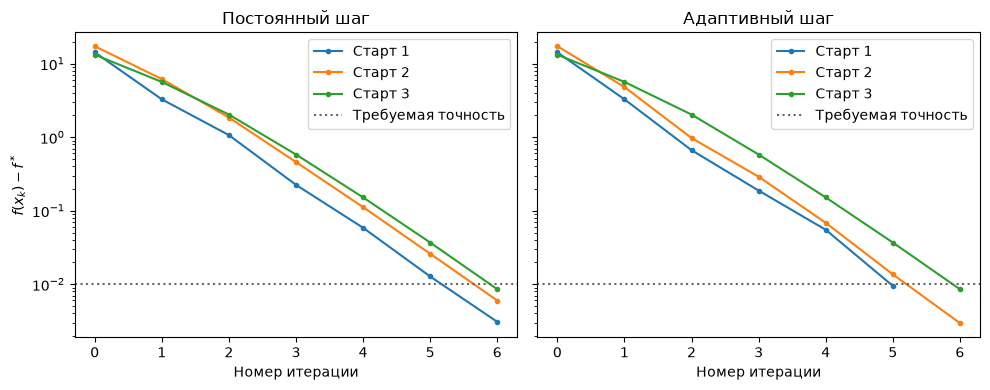

,Шаг,Старт,Итерации,Конечная ошибка,Точность достигнута,Проверки при подборе шага
0,Постоянный шаг,1,6,0.003072,True,0
1,Постоянный шаг,2,6,0.005990,True,0
2,Постоянный шаг,3,6,0.008535,True,0
3,Адаптивный шаг,1,5,0.009491,True,17
4,Адаптивный шаг,2,6,0.002953,True,17
5,Адаптивный шаг,3,6,0.008535,True,18


In [19]:
plane_adaptive = adaptive_heavy_ball(
    plane_problem, plane_start, plane_value, plane_L, plane_mu, keep_history=True
)
paths["Адаптивный шаг"] = np.array(plane_adaptive.trajectory)
plot_trajectories(paths)

samples["Адаптивный шаг"] = example_runs(adaptive_heavy_ball)
plot_accuracy(samples)

При $n=2$ подбор шага сократил число итераций с 11 до 9.
В примере с $n=10$ он сэкономил один шаг на первом старте;
на двух остальных число шагов не изменилось.

,Число пар
Меньше итераций с подбором,6558
Столько же итераций,38031
Больше итераций с подбором,5411


iterations                                time_ms  \
method Тяжелый шарик Тяжелый шарик с подбором Тяжелый шарик   
n                                                             
10             6.074                    5.639         0.047   
20             6.597                    6.357         0.052   
30             6.946                    6.849         0.056   
40             7.197                    7.135         0.057   
50             7.235                    7.224         0.059   
60             7.412                    7.470         0.061   
70             7.502                    7.613         0.063   
80             7.671                    7.768         0.067   
90             7.775                    7.878         0.070   
100            7.841                    7.947         0.072   

                                 
method Тяжелый шарик с подбором  
n                                
10                        0.115  
20                        0.134  
30                        0.138  
40                        0.147  
50                        0.152  
60                        0.151  
70                        0.155  
80                        0.162  
90                        0.166  
100                       0.171

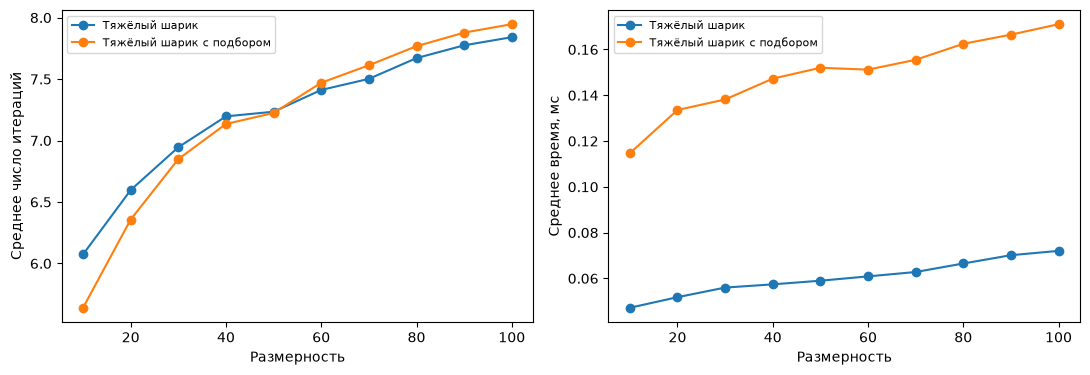

In [20]:
def compare_iterations(runs, fixed_label, adaptive_label):
    # Сравниваем методы попарно на одной задаче и одной начальной точке
    paired_iterations = runs.pivot(
        index=["problem", "start"], columns="method", values="iterations"
    )
    saved_iterations = paired_iterations[fixed_label] - paired_iterations[adaptive_label]
    return pd.Series({
        "Меньше итераций с подбором": (saved_iterations > 0).sum(),
        "Столько же итераций": (saved_iterations == 0).sum(),
        "Больше итераций с подбором": (saved_iterations < 0).sum(),
    }, name="Число пар").to_frame()


adaptive_label = "Тяжелый шарик с подбором"
strong_adaptive = benchmark(strong_indices, adaptive_label, adaptive_heavy_ball)
strong_both = pd.concat([strong_runs, strong_adaptive], ignore_index=True)
display(compare_iterations(strong_both, fixed_label, adaptive_label))
strong_by_n = summarize_by_n(strong_both)
display(strong_by_n.unstack("method").round(3))
plot_by_n(strong_by_n)

#### Нестеров

При изменении $M$ пересчитываем $\beta$, затем $y=x+\beta(x-x_{\rm prev})$
и $\nabla f(y)$. Условие для точки $z=y-\nabla f(y)/M$ проверяем относительно $y$:

$$f(z)\le f(y)-\frac{\|\nabla f(y)\|_2^2}{2M}.$$

Если шаг не подошел, пробуем градиентный шаг из $x$ с условием из предыдущего
подпункта. После двух отказов удваиваем $M$.
При $\mu=0$ коэффициент $\beta_k=k/(k+3)$ зависит только от номера шага.

In [21]:
def adaptive_nesterov_step(problem, x, value, displacement, M, L, mu, iterations=0):
    M = max(M / 2.0, mu, L * np.finfo(float).eps)
    checks = 0
    trial_L_sum = 0.0
    # Точка x не меняется внутри подбора, поэтому ее градиент считаем один раз
    grad_x = gradient(problem, x)
    grad_x_squared = grad_x @ grad_x

    rounds = 0
    while True:
        rounds += 1
        step, beta = nesterov_parameters(M, mu)
        cur_beta = beta if beta is not None else iterations / (iterations + 3.0)
        # При новом M пересчитываем beta, точку y и градиент в y
        y = x + cur_beta * displacement
        val_y = objective(problem, y)
        grad_y = gradient(problem, y)

        candidate_nag = y - step * grad_y
        val_nag = objective(problem, candidate_nag)
        checks += 1
        trial_L_sum += M
        if val_nag <= val_y - (grad_y @ grad_y) / (2.0 * M):
            return candidate_nag, val_nag, M, checks, trial_L_sum, rounds

        # При отказе проверяем градиентный шаг из текущей точки x
        candidate_gd = x - grad_x / M
        val_gd = objective(problem, candidate_gd)
        checks += 1
        trial_L_sum += M
        if val_gd <= value - grad_x_squared / (2.0 * M):
            return candidate_gd, val_gd, M, checks, trial_L_sum, rounds
        M *= 2.0


def adaptive_nesterov(
    problem, x0, f_star, L, mu, eps=0.01, keep_history=False, max_iter=10000
):
    return run_nesterov(
        problem, x0, f_star, L, mu, eps=eps, keep_history=keep_history,
        max_iter=max_iter, adaptive=True,
    )

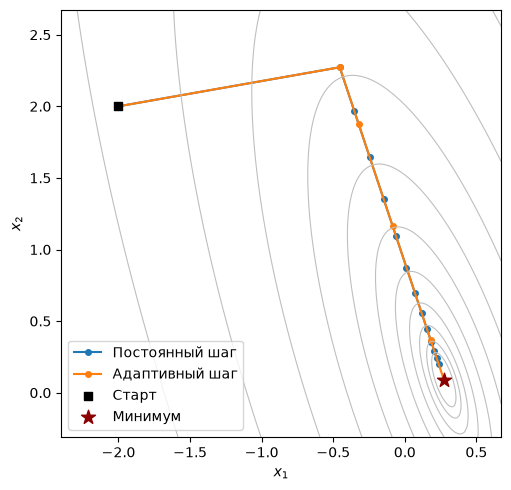

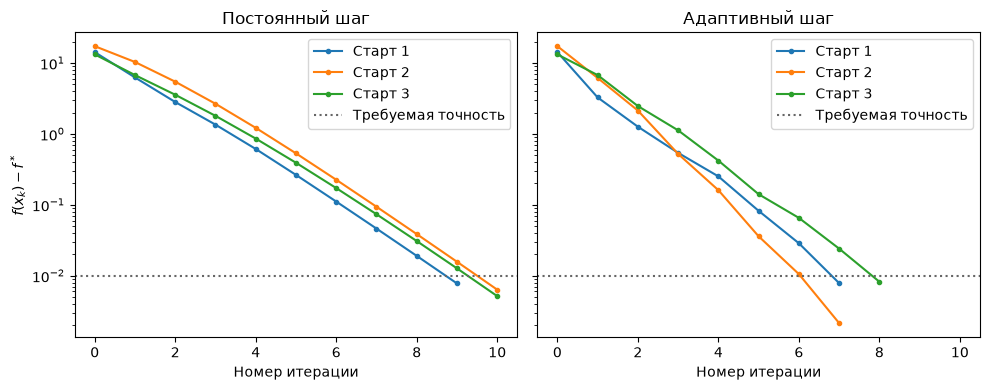

,Шаг,Старт,Итерации,Конечная ошибка,Точность достигнута,Проверки при подборе шага
0,Постоянный шаг,1,9,0.007762,True,0
1,Постоянный шаг,2,10,0.006339,True,0
2,Постоянный шаг,3,10,0.005142,True,0
3,Адаптивный шаг,1,7,0.007848,True,24
4,Адаптивный шаг,2,7,0.002142,True,21
5,Адаптивный шаг,3,8,0.008209,True,24


In [22]:
plane_nest = run_nesterov(
    plane_problem, plane_start, plane_value, plane_L, plane_mu, keep_history=True
)
plane_adaptive_nest = adaptive_nesterov(
    plane_problem, plane_start, plane_value, plane_L, plane_mu, keep_history=True
)
paths_nest = {"Постоянный шаг": np.array(plane_nest.trajectory)}
paths_nest["Адаптивный шаг"] = np.array(plane_adaptive_nest.trajectory)
plot_trajectories(paths_nest)

samples_nest = {"Постоянный шаг": example_runs(run_nesterov)}
samples_nest["Адаптивный шаг"] = example_runs(adaptive_nesterov)
plot_accuracy(samples_nest)

В таблице сравниваются одни и те же три старта. При подборе $M$ меняются
точка $y$ и ее градиент, поэтому один внешний шаг может требовать нескольких
попыток. Это нужно учитывать при сравнении времени.

,Число пар
Меньше итераций с подбором,49556
Столько же итераций,428
Больше итераций с подбором,16


iterations                                    time_ms  \
method Метод Нестерова Метод Нестерова с подбором Метод Нестерова   
n                                                                   
10               8.706                      6.391           0.064   
20               9.931                      7.753           0.073   
30              10.719                      8.521           0.079   
40              11.192                      8.987           0.083   
50              11.331                      9.044           0.086   
60              11.817                      9.478           0.092   
70              11.976                      9.541           0.096   
80              12.242                      9.741           0.100   
90              12.334                      9.800           0.108   
100             12.464                      9.863           0.111   

                                   
method Метод Нестерова с подбором  
n                                  
10                          0.184  
20                          0.226  
30                          0.253  
40                          0.270  
50                          0.277  
60                          0.296  
70                          0.305  
80                          0.317  
90                          0.336  
100                         0.357

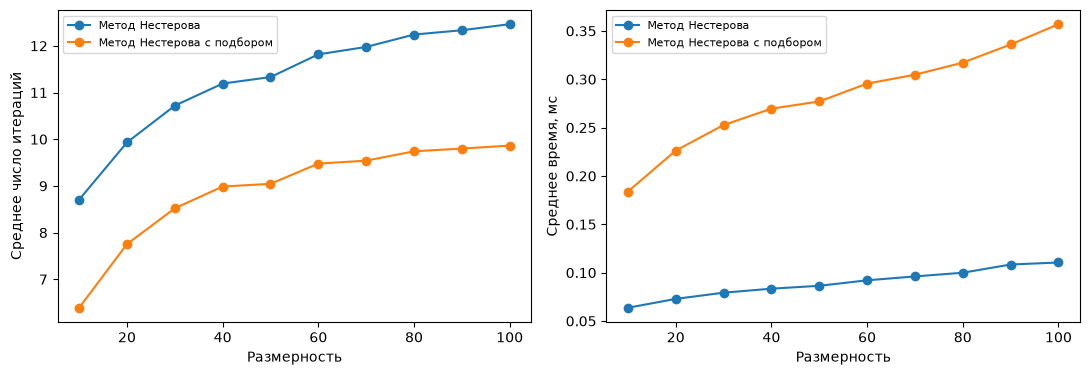

In [23]:
fixed_label_nest = "Метод Нестерова"
adaptive_label_nest = "Метод Нестерова с подбором"
strong_runs_nest = benchmark(strong_indices, fixed_label_nest, run_nesterov)
strong_adaptive_nest = benchmark(strong_indices, adaptive_label_nest, adaptive_nesterov)
strong_both_nest = pd.concat([strong_runs_nest, strong_adaptive_nest], ignore_index=True)
display(compare_iterations(strong_both_nest, fixed_label_nest, adaptive_label_nest))
strong_by_n_nest = summarize_by_n(strong_both_nest)
display(strong_by_n_nest.unstack("method").round(3))
plot_by_n(strong_by_n_nest)

Подбор шага уменьшил среднее число итераций Нестерова во всех размерностях,
но увеличил время. Причина - дополнительные вычисления функции и градиента
при поиске $M$.

### 4e. Как скорость зависит от $\mu/L$

Рассмотрим $\mu>0$ и обозначим $r=\mu/L$, $e_k=x_k-x^*$.
Так как $\nabla f(x^*)=0$, имеем $\nabla f(x_k)=He_k$.

Матрица $H$ симметрична, поэтому $H=Q\Lambda Q^\top$, где столбцы $Q$ -
ортонормированные собственные векторы, а $\Lambda$ содержит собственные значения
$\lambda_i\in[\mu,L]$. В координатах $z_k=Q^\top e_k$ направления независимы.
Рассмотрим одно из них с собственным значением $\lambda$.

#### Тяжелый шарик

Вычтем $x^*$ из формулы шага и подставим $\nabla f(x_k)=He_k$:

$$e_{k+1}=(I-hH+\beta I)e_k-\beta e_{k-1}.$$

В одном собственном направлении это дает

$$z_{k+1}=(1-h\lambda+\beta)z_k-\beta z_{k-1}.$$

Чтобы найти скорость, подставим $z_k=t^k$:

$$t^2-(1-h\lambda+\beta)t+\beta=0.$$

При параметрах Поляка обозначим
$\rho=(\sqrt L-\sqrt\mu)/(\sqrt L+\sqrt\mu)$, тогда $\beta=\rho^2$.
Коэффициент $c(\lambda)=1-h\lambda+\beta$ убывает от $c(\mu)=2\rho$
до $c(L)=-2\rho$. Поэтому дискриминант $c(\lambda)^2-4\rho^2\le0$.

Комплексные корни имеют произведение $\rho^2$ и модуль $\rho$;
на границах получаются кратные корни $\rho$ или $-\rho$. Значит,

$$\rho_{\rm HB}=\frac{\sqrt L-\sqrt\mu}{\sqrt L+\sqrt\mu}
=\frac{1-\sqrt r}{1+\sqrt r}.$$

Чем меньше модуль корней, тем быстрее затухают составляющие ошибки.

#### Нестеров

Сначала запишем ошибку в точке сдвига:
$y_k-x^*=(1+\beta)e_k-\beta e_{k-1}$. После градиентного шага получаем

$$e_{k+1}=\left(I-\frac HL\right)
\bigl((1+\beta)e_k-\beta e_{k-1}\bigr).$$

Для одного собственного направления

$$z_{k+1}=\left(1-\frac\lambda L\right)
\bigl((1+\beta)z_k-\beta z_{k-1}\bigr).$$

Положим $s=\sqrt{\mu/L}$, $u=1-\lambda/L$.
Из $\mu\le\lambda\le L$ следует $0\le u\le1-s^2$,
а коэффициент инерции равен $\beta=(1-s)/(1+s)$.
Подстановка $z_k=t^k$ дает

$$t^2-u(1+\beta)t+u\beta=0.$$

Дискриминант неположителен:

$$D=u\bigl(u(1+\beta)^2-4\beta\bigr)\le0,
\qquad 1-s^2=\frac{4\beta}{(1+\beta)^2}.$$

Поэтому модуль корней ограничен величиной

$$|t|=\sqrt{u\beta}\le
\sqrt{(1-s^2)\frac{1-s}{1+s}}=1-s.$$

При $\lambda=\mu$ граница достигается, откуда

$$\rho_{\rm N}=1-\sqrt{\mu/L}=1-\sqrt r.$$

Если $\mu=L$, то $H=LI$, оба метода имеют $\beta=0$, $h=1/L$
и приходят в минимум за один шаг.

У обоих методов рост $\mu/L$ уменьшает $\rho$ и улучшает скорость в худшем случае.
При $\mu/L\to0$ оба значения $\rho$ стремятся к единице, и сходимость замедляется.
Кратные корни могут добавлять множитель $k$ к ошибке точки;
это учтем в оценках числа итераций ниже.

### 4f. Локальные оценки $L$ и стоимость подбора шага

Посчитаем два средних значения $M$: по принятым шагам и по всем проверенным
пробным шагам, включая отклоненные. Для каждой траектории делим среднее на ее $L$,
затем усредняем отношения по запускам.

Один проход внутреннего цикла соответствует одному значению $M$.
В нем могут проверяться два шага, поэтому число проходов и число проверок различаются.
В таблицах делим их суммы на число внешних итераций.
Для Нестерова в `checks` считаются проверки точек $z$; вычисления в $y$
нужны дополнительно и тоже влияют на время.

In [24]:
def summarize_steps(runs):
    # Старты без шагов исключаем, чтобы не делить на ноль при усреднении
    adaptive_runs = runs[runs["iterations"] > 0].copy()
    adaptive_runs["accepted_L"] = adaptive_runs["accepted_L_sum"] / adaptive_runs["iterations"]
    adaptive_runs["trial_L"] = adaptive_runs["trial_L_sum"] / adaptive_runs["checks"]
    # Сначала нормируем по L своей задачи, затем усредняем по траекториям
    adaptive_runs["accepted_ratio"] = adaptive_runs["accepted_L"] / adaptive_runs["L"]
    adaptive_runs["trial_ratio"] = adaptive_runs["trial_L"] / adaptive_runs["L"]

    step_summary = adaptive_runs.groupby("mu").agg(
        global_L=("L", "mean"),
        accepted_L=("accepted_L", "mean"),
        trial_L=("trial_L", "mean"),
        accepted_ratio=("accepted_ratio", "mean"),
        trial_ratio=("trial_ratio", "mean"),
        rounds=("rounds", "sum"),
        checks=("checks", "sum"),
        iterations=("iterations", "sum")
    )
    # Число внутренних проходов и проверок делим на общее число внешних шагов
    step_summary["rounds_per_iteration"] = step_summary["rounds"] / step_summary["iterations"]
    step_summary["checks_per_iteration"] = step_summary["checks"] / step_summary["iterations"]
    return step_summary[
        ["global_L", "accepted_L", "trial_L", "accepted_ratio", "trial_ratio",
         "rounds_per_iteration", "checks_per_iteration"]
    ]


step_labels = {
    "rounds_per_iteration": "Итераций внутреннего цикла на внешний шаг",
    "checks_per_iteration": "Проверок пробного шага на внешний шаг",
}
summarize_steps(strong_adaptive).rename(columns=step_labels).round(3)

,global_L,accepted_L,trial_L,accepted_ratio,trial_ratio,Итераций внутреннего цикла на внешний шаг,Проверок пробного шага на внешний шаг
mu,,,,,,,
1.0,6.258,5.893,3.971,0.942,0.635,1.993,3.064


Для тяжелого шарика при $\mu=1$ средняя принятая оценка составляет 0,942 от $L$,
а средняя по всем пробам - 0,635 от $L$. На внешний шаг приходится
около 1,99 прохода подбора и 3,06 проверки пробного шага.

In [25]:
display(summarize_steps(strong_adaptive_nest).rename(columns=step_labels).round(3))

,global_L,accepted_L,trial_L,accepted_ratio,trial_ratio,Итераций внутреннего цикла на внешний шаг,Проверок пробного шага на внешний шаг
mu,,,,,,,
1.0,6.258,4.264,2.946,0.683,0.472,1.923,3.105


У Нестерова принятые оценки в среднем составляют 0,683 от $L$,
а оценки по всем пробам - 0,472 от $L$. На внешний шаг приходится
около 1,92 прохода подбора и 3,11 проверки. Меньшее $M$ позволяет сделать
более длинный шаг, но его поиск требует дополнительных вычислений.

### 4g. Случай $\mu=0$

Если подставить $\mu=0$ в параметры Поляка, получим $h=4/L$, $\beta=1$.
При $\lambda=L$ уравнение для ошибки имеет вид $(t+1)^2=0$:
корни по модулю равны единице, а из-за их кратности ошибка может расти.
Поэтому берем $h=1/L$ и $\beta=1/2$.

Проверим сходимость при таком выборе. Для $\lambda>0$ имеем $0<h\lambda\le1$
и уравнение

$$t^2-(1+\beta-h\lambda)t+\beta=0.$$

У комплексных корней модуль $\sqrt\beta<1$. Вещественные корни положительны,
их произведение $\beta<1$, а значение многочлена при $t=1$ равно
$h\lambda>0$. Значит, оба корня меньше единицы. В направлениях с $\lambda=0$
начальная скорость равна нулю, и компонента точки не меняется.

Поэтому ошибка по функции стремится к нулю, хотя на отдельных шагах она может
возрастать. Сравним постоянный и адаптивный шаги в обеих группах задач.

In [26]:
def heavy_ball_parameters(L, mu):
    # При mu = 0 формула Поляка дает beta = 1, поэтому используем устойчивый вариант
    if mu == 0:
        return 1 / L, 0.5
    return polyak_parameters(L, mu)


def heavy_ball(
    problem, x0, f_star, L, mu, eps=0.01,
    adaptive=False, keep_history=False, max_iter=10000
):
    return run_heavy_ball(
        problem, x0, f_star, L, mu, eps=eps, keep_history=keep_history, max_iter=max_iter,
        parameters=heavy_ball_parameters, adaptive=adaptive
    )

In [27]:
flat_indices = results.index[results["mu"] == 0]
flat_fixed = benchmark(flat_indices, fixed_label, heavy_ball)
flat_adaptive = benchmark(flat_indices, adaptive_label, partial(heavy_ball, adaptive=True))
hb_runs = pd.concat([strong_both, flat_fixed, flat_adaptive], ignore_index=True)
print(f"Выполнено запусков: {len(hb_runs)}")
print(f"Требуемая точность достигнута: {hb_runs['converged'].sum()}")

Выполнено запусков: 200000
Требуемая точность достигнута: 200000


Для тяжелого шарика объединим обе группы и сравним результаты по размерности и по значению $\mu$.

iterations                                time_ms  \
method Тяжелый шарик Тяжелый шарик с подбором Тяжелый шарик   
n                                                             
10            10.005                    6.066         0.076   
20            13.366                    7.882         0.099   
30            12.024                    8.252         0.092   
40            13.231                    8.792         0.102   
50            14.813                    9.389         0.123   
60            15.881                    9.819         0.128   
70            16.256                   10.024         0.130   
80            16.911                   10.296         0.137   
90            16.757                   10.374         0.141   
100           17.962                   10.716         0.154   

                                 
method Тяжелый шарик с подбором  
n                                
10                        0.113  
20                        0.150  
30                        0.153  
40                        0.170  
50                        0.184  
60                        0.190  
70                        0.198  
80                        0.204  
90                        0.212  
100                       0.221

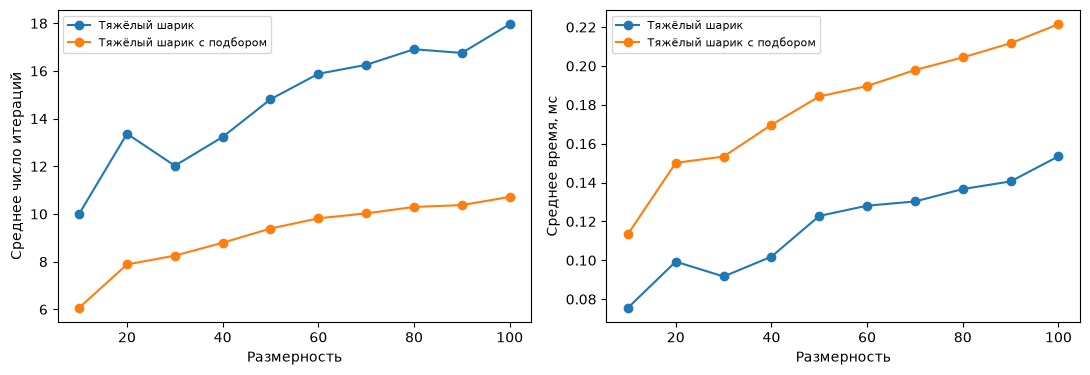

,Число пар
Меньше итераций с подбором,56505
Столько же итераций,38065
Больше итераций с подбором,5430


,global_L,accepted_L,trial_L,accepted_ratio,trial_ratio,Итераций внутреннего цикла на внешний шаг,Проверок пробного шага на внешний шаг
mu,,,,,,,
0.0,5.265,2.786,2.023,0.531,0.386,1.887,2.991
1.0,6.258,5.893,3.971,0.942,0.635,1.993,3.064


In [28]:
hb_by_n = summarize_by_n(hb_runs)
display(hb_by_n.unstack("method").round(3))
plot_by_n(hb_by_n)
display(compare_iterations(hb_runs, fixed_label, adaptive_label))

step_summary = summarize_steps(hb_runs[hb_runs["method"] == adaptive_label])
display(step_summary.rename(columns=step_labels).round(3))

In [29]:
hb_by_mu = hb_runs.groupby(["mu", "method"], sort=False).agg(
    runs=("converged", "size"),
    converged=("converged", "sum"),
    iterations=("iterations", "mean"),
    time_ms=("time_ms", "mean")
)
hb_by_mu.round(3)

runs  converged  iterations  time_ms
mu  method                                                         
1.0 Тяжелый шарик             50000      50000       7.225    0.060
    Тяжелый шарик с подбором  50000      50000       7.188    0.149
0.0 Тяжелый шарик             50000      50000      22.216    0.176
    Тяжелый шарик с подбором  50000      50000      11.134    0.210

При $\mu=0$ подбор шага сократил среднее число итераций с 22,22 до 11,13.
При $\mu=1$ разница небольшая: 7,22 против 7,19.
В обеих группах постоянный шаг оказался быстрее по времени.

#### Нестеров при $\mu=0$

Используем $h=1/L$ и $\beta_k=k/(k+3)$. Для постоянного шага известна оценка

$$f(x_k)-f^*\le\frac{2L\|x_0-x^\dagger\|^2}{(k+1)^2},$$

где $x^\dagger$ - ближайшая к $x_0$ точка минимума.
Сравним оба варианта Нестерова с тяжелым шариком на тех же 50 000 стартах.

Здесь минимум неединственный. Градиент лежит в $\operatorname{range}(A^\top)$,
поэтому все методы сохраняют компоненту $x_0$ в $\ker A$ и могут прийти
в точку, отличную от решения CVXPY. По этой причине сравниваем именно
$f(x_k)-f^*$, а не расстояние до найденного решателем минимума.

Хотя глобальная $\mu=0$, для каждой нашей матрицы наименьшее положительное
собственное значение $A^\top A$ больше нуля. В направлениях с ненулевой
кривизной это допускает линейную сходимость - быстрее общей оценки для выпуклых функций.

In [30]:
flat_fixed_nest = benchmark(flat_indices, fixed_label_nest, run_nesterov)
flat_adaptive_nest = benchmark(flat_indices, adaptive_label_nest, adaptive_nesterov)
nest_runs = pd.concat([strong_both_nest, flat_fixed_nest, flat_adaptive_nest], ignore_index=True)
flat_comparison = pd.concat([hb_runs, nest_runs], ignore_index=True).query("mu == 0")
display(flat_comparison.groupby("method", sort=False).agg(
    runs=("converged", "size"),
    converged=("converged", "sum"),
    iterations=("iterations", "mean"),
    time_ms=("time_ms", "mean")
).round(3))

# Дополняем пункт 4f оценками Нестерова для обеих групп, включая mu = 0
nest_step_summary = summarize_steps(nest_runs[nest_runs["method"] == adaptive_label_nest])
print("Оценки L и подбор шага Нестерова (4f)")
display(nest_step_summary.rename(columns=step_labels).round(3))

,runs,converged,iterations,time_ms
method,,,,
Тяжелый шарик,50000,50000,22.216,0.176
Тяжелый шарик с подбором,50000,50000,11.134,0.210
Метод Нестерова,50000,50000,16.825,0.133
Метод Нестерова с подбором,50000,50000,14.973,0.467


Оценки L и подбор шага Нестерова (4f)


,global_L,accepted_L,trial_L,accepted_ratio,trial_ratio,Итераций внутреннего цикла на внешний шаг,Проверок пробного шага на внешний шаг
mu,,,,,,,
0.0,5.265,2.980,2.083,0.567,0.397,1.928,3.432
1.0,6.258,4.264,2.946,0.683,0.472,1.923,3.105


Все 200 000 запусков достигли точности. При подборе шага среднее число
итераций тяжелого шарика уменьшилось с 22,22 до 11,13,
а Нестерова - с 16,83 до 14,97. По времени оба адаптивных варианта медленнее.
Оценка $O(1/k^2)$ у Нестерова описывает худший случай для класса функций;
она не означает, что на каждой задаче он будет быстрее другого метода.

Последняя таблица дополняет пункт 4f: показывает локальные оценки $L$
и стоимость подбора шага Нестерова также при $\mu=0$.

### 4h. Сравнение с градиентным спуском

Добавим обычный градиентный спуск с постоянным шагом:

$$x_{k+1}=x_k-\frac1L\nabla f(x_k).$$

Используем цикл тяжелого шарика с $\beta=0$ и $h=1/L$.
Задачи, старты и критерий остановки оставляем теми же.
Замеряем только работу метода: без генерации данных, CVXPY, вычисления $L$, $\mu$
и построения графиков. Сохранение траектории при замерах отключено.

In [31]:
def run_gradient_descent(
    problem, x0, f_star, L, mu, eps=0.01, keep_history=False, max_iter=10000
):
    # Нулевая инерция превращает общий цикл в обычный градиентный спуск
    return run_heavy_ball(
        problem, x0, f_star, L, mu, eps=eps, keep_history=keep_history,
        max_iter=max_iter, parameters=lambda L, mu: (1 / L, 0.0)
    )


gd_label = "Градиентный спуск (1/L)"
gd_runs = benchmark(results.index, gd_label, run_gradient_descent)
comparison_runs = pd.concat([hb_runs, nest_runs, gd_runs], ignore_index=True)

#### Средние результаты по размерностям (4b)

Сначала для каждого $n$ усредняем по всем 100 задачам и 100 стартам -
10 000 запусков каждого метода, как требуется в условии.
Затем разделяем результаты по $\mu$: в каждой группе по 50 задач и 100 стартам.
Так можно увидеть, как сильная выпуклость влияет на сравнение.

Все 100 задач каждой размерности


iterations                                           \
method Тяжелый шарик Тяжелый шарик с подбором Метод Нестерова   
n                                                               
10            10.005                    6.066           9.093   
20            13.366                    7.882          11.500   
30            12.024                    8.252          12.041   
40            13.231                    8.792          12.990   
50            14.813                    9.389          14.118   
60            15.881                    9.819          14.796   
70            16.256                   10.024          15.572   
80            16.911                   10.296          16.151   
90            16.757                   10.374          16.839   
100           17.962                   10.716          17.383   

                                                                time_ms  \
method Метод Нестерова с подбором Градиентный спуск (1/L) Тяжелый шарик   
n                                                                         
10                          7.141                  21.252         0.076   
20                         10.153                  30.500         0.099   
30                         10.125                  28.890         0.092   
40                         11.168                  32.112         0.102   
50                         12.128                  35.671         0.123   
60                         13.052                  38.441         0.128   
70                         13.181                  39.459         0.130   
80                         13.861                  40.968         0.137   
90                         13.940                  40.870         0.141   
100                        14.673                  43.302         0.154   

                                                                            \
method Тяжелый шарик с подбором Метод Нестерова Метод Нестерова с подбором   
n                                                                            
10                        0.113           0.069                      0.198   
20                        0.150           0.088                      0.293   
30                        0.153           0.089                      0.298   
40                        0.170           0.097                      0.333   
50                        0.184           0.106                      0.370   
60                        0.190           0.113                      0.405   
70                        0.198           0.125                      0.420   
80                        0.204           0.131                      0.450   
90                        0.212           0.142                      0.470   
100                       0.221           0.149                      0.511   

                                
method Градиентный спуск (1/L)  
n                               
10                       0.148  
20                       0.211  
30                       0.208  
40                       0.237  
50                       0.266  
60                       0.293  
70                       0.307  
80                       0.319  
90                       0.328  
100                      0.359

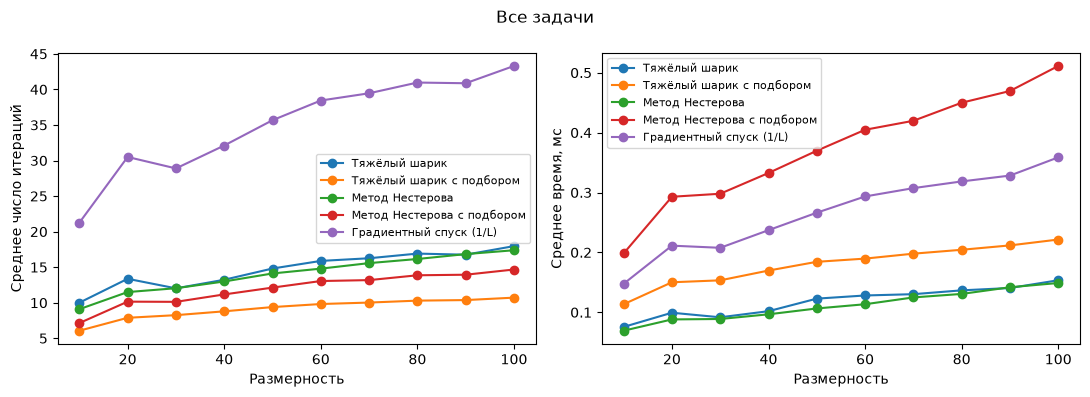

mu = 0; запусков каждого метода на размерность: 5000


iterations                                           \
method Тяжелый шарик Тяжелый шарик с подбором Метод Нестерова   
n                                                               
10            13.936                    6.492           9.480   
20            20.135                    9.407          13.070   
30            17.102                    9.655          13.362   
40            19.266                   10.450          14.787   
50            22.391                   11.554          16.905   
60            24.351                   12.167          17.774   
70            25.010                   12.436          19.167   
80            26.152                   12.824          20.061   
90            25.739                   12.869          21.344   
100           28.084                   13.486          22.302   

                                                                time_ms  \
method Метод Нестерова с подбором Градиентный спуск (1/L) Тяжелый шарик   
n                                                                         
10                          7.891                  26.448         0.104   
20                         12.552                  41.961         0.147   
30                         11.729                  36.647         0.127   
40                         13.350                  41.791         0.146   
50                         15.211                  48.658         0.187   
60                         16.627                  52.872         0.195   
70                         16.821                  54.480         0.198   
80                         17.982                  56.734         0.207   
90                         18.080                  56.216         0.211   
100                        19.482                  60.857         0.235   

                                                                            \
method Тяжелый шарик с подбором Метод Нестерова Метод Нестерова с подбором   
n                                                                            
10                        0.112           0.075                      0.213   
20                        0.167           0.103                      0.360   
30                        0.169           0.098                      0.343   
40                        0.192           0.110                      0.396   
50                        0.217           0.126                      0.462   
60                        0.228           0.135                      0.514   
70                        0.240           0.154                      0.535   
80                        0.246           0.161                      0.583   
90                        0.257           0.175                      0.603   
100                       0.272           0.187                      0.666   

                                
method Градиентный спуск (1/L)  
n                               
10                       0.183  
20                       0.289  
30                       0.260  
40                       0.307  
50                       0.362  
60                       0.402  
70                       0.424  
80                       0.440  
90                       0.450  
100                      0.498

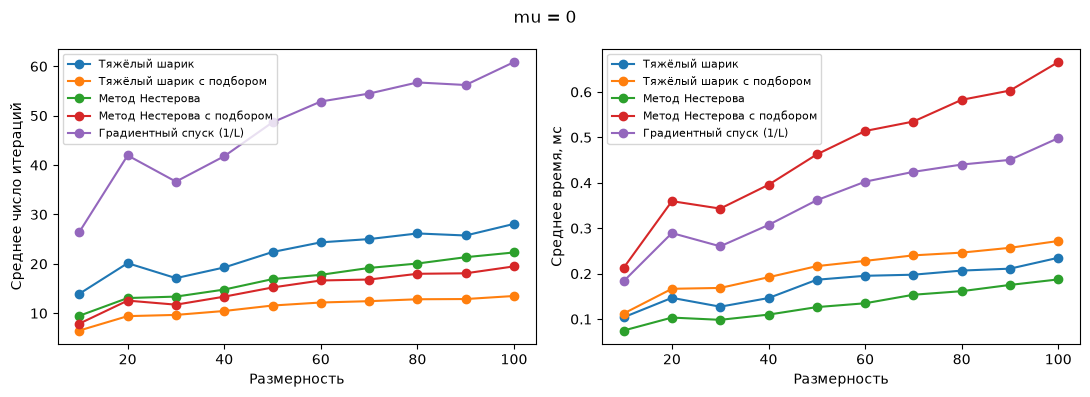

mu = 1; запусков каждого метода на размерность: 5000


iterations                                           \
method Тяжелый шарик Тяжелый шарик с подбором Метод Нестерова   
n                                                               
10             6.074                    5.639           8.706   
20             6.597                    6.357           9.931   
30             6.946                    6.849          10.719   
40             7.197                    7.135          11.192   
50             7.235                    7.224          11.331   
60             7.412                    7.470          11.817   
70             7.502                    7.613          11.976   
80             7.671                    7.768          12.242   
90             7.775                    7.878          12.334   
100            7.841                    7.947          12.464   

                                                                time_ms  \
method Метод Нестерова с подбором Градиентный спуск (1/L) Тяжелый шарик   
n                                                                         
10                          6.391                  16.056         0.047   
20                          7.753                  19.039         0.052   
30                          8.521                  21.133         0.056   
40                          8.987                  22.433         0.057   
50                          9.044                  22.684         0.059   
60                          9.478                  24.009         0.061   
70                          9.541                  24.437         0.063   
80                          9.741                  25.201         0.067   
90                          9.800                  25.523         0.070   
100                         9.863                  25.747         0.072   

                                                                            \
method Тяжелый шарик с подбором Метод Нестерова Метод Нестерова с подбором   
n                                                                            
10                        0.115           0.064                      0.184   
20                        0.134           0.073                      0.226   
30                        0.138           0.079                      0.253   
40                        0.147           0.083                      0.270   
50                        0.152           0.086                      0.277   
60                        0.151           0.092                      0.296   
70                        0.155           0.096                      0.305   
80                        0.162           0.100                      0.317   
90                        0.166           0.108                      0.336   
100                       0.171           0.111                      0.357   

                                
method Градиентный спуск (1/L)  
n                               
10                       0.112  
20                       0.133  
30                       0.155  
40                       0.167  
50                       0.171  
60                       0.184  
70                       0.191  
80                       0.197  
90                       0.206  
100                      0.219

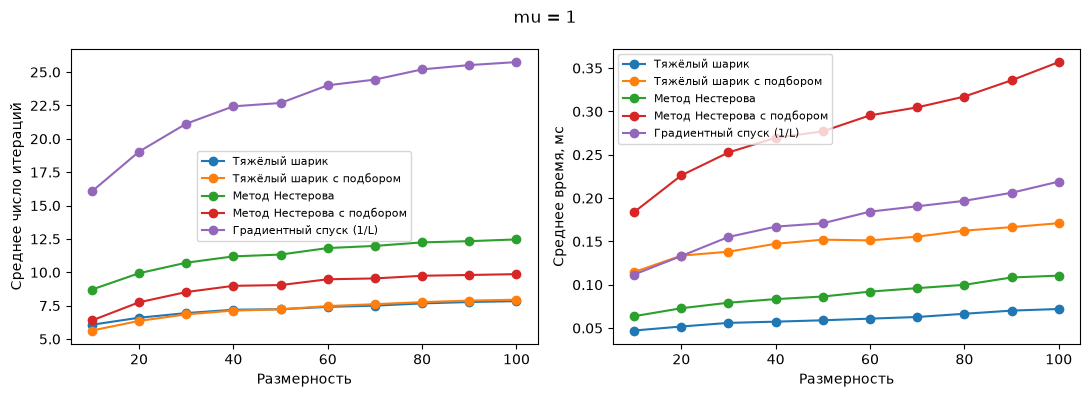

In [32]:
# Общее среднее по всем тестовым задачам каждой размерности
all_by_n = summarize_by_n(comparison_runs)
print("Все 100 задач каждой размерности")
display(all_by_n.unstack("method").round(3))
plot_by_n(all_by_n, "Все задачи")

# Отдельные группы помогают объяснить различия между методами
for mu, runs in comparison_runs.groupby("mu", sort=True):
    starts_per_n = EXAMPLES_PER_GROUP * STARTS_PER_PROBLEM
    print(f"mu = {mu:g}; запусков каждого метода на размерность: {starts_per_n}")
    by_n = summarize_by_n(runs)
    display(by_n.unstack("method").round(3))
    plot_by_n(by_n, f"mu = {mu:g}")

#### Сравнение с теорией (4b)

Обозначим $E_k=f(x_k)-f^*$, $R=\|x_0-x^\dagger\|$ и
$\kappa=L/\mu$ при $\mu>0$. Для постоянных шагов получаем:

| Метод | При $\mu>0$ | При $\mu=0$ |
|---|---|---|
| Градиентный спуск, $1/L$ | $E_k\le E_0(1-\mu/L)^{2k}$ | $E_k\le LR^2/(2k)$, $k\ge1$ |
| Тяжелый шарик | $\rho=(\sqrt\kappa-1)/(\sqrt\kappa+1)$, $E_k=O(k^2\rho^{2k})$ | При $h=1/L$, $\beta=1/2$ ошибка по функции стремится к нулю |
| Нестеров | $\rho=1-1/\sqrt\kappa$, $E_k=O(k^2\rho^{2k})$ для нашей квадратичной функции | $E_k\le2LR^2/(k+1)^2$ |

У градиентного спуска при $\mu>0$ число шагов оценивается как
$O(\kappa\log(E_0/\varepsilon))$. У ускоренных методов основной множитель
равен $\sqrt\kappa$. В пункте 4e получили скорость уменьшения ошибки точки;
ошибка квадратичной функции содержит квадрат этого множителя - $\rho^{2k}$.
При кратных корнях появляется также множитель $k^2$.

Для численного сравнения при $\mu>0$ используем верхнюю оценку обоих ускоренных методов:

$$E_k\le E_0[1+(1+\rho)k]^2\rho^{2k}.$$

Она получается из уравнений пункта 4e при $x_{-1}=x_0$:
модуль множителя ошибки в каждом собственном направлении не больше
$[k+1+\rho k]\rho^k$. Для каждого старта находим первое $k$, при котором
верхняя оценка достигает $0.01$, затем усредняем эти числа.
Для градиентного спуска используем первую строку таблицы.
Адаптивные варианты в эту оценку не подставляем: у них шаг меняется по ходу работы.

In [33]:
theory_rows = []
for i in strong_indices:
    meta = results.loc[i]
    errors0 = np.array([objective(problems[i], x0) - meta["f_star"] for x0 in initial_points[i]])
    ratio = meta["mu"] / meta["L"]
    factors = {
        gd_label: 1 - ratio,
        fixed_label: (1 - np.sqrt(ratio)) / (1 + np.sqrt(ratio)),
        fixed_label_nest: 1 - np.sqrt(ratio),
    }
    for method, rho in factors.items():
        steps = np.zeros(len(errors0), dtype=int)
        while True:
            multiplier = 1 if method == gd_label else (1 + (1 + rho) * steps)**2
            # Добавляем шаг только тем стартам, где оценка ошибки еще выше допуска
            pending = (errors0 > accuracy) & (errors0 * multiplier * rho**(2 * steps) > accuracy)
            if not pending.any():
                break
            steps[pending] += 1
        theory_rows.append((meta["n"], method, steps.mean()))

theory_by_n = (
    pd.DataFrame(theory_rows, columns=["n", "method", "upper_iterations"])
    .groupby(["n", "method"]).mean()
)
observed = summarize_by_n(comparison_runs.query("mu > 0"))["iterations"]
theory_comparison = theory_by_n.join(observed).rename(columns={
    "iterations": "Среднее число итераций",
    "upper_iterations": "Средняя верхняя оценка",
})
display(theory_comparison.round(3).unstack("method"))

Средняя верхняя оценка                                \
method Градиентный спуск (1/L) Метод Нестерова Тяжелый шарик   
n                                                              
10                      18.984          12.483         7.064   
20                      22.097          13.885         7.838   
30                      24.255          14.789         8.366   
40                      25.801          15.438         8.687   
50                      25.937          15.467         8.753   
60                      27.231          15.996         9.025   
70                      27.618          16.122         9.075   
80                      28.444          16.446         9.223   
90                      28.871          16.632         9.282   
100                     28.997          16.639         9.388   

        Среднее число итераций                                
method Градиентный спуск (1/L) Метод Нестерова Тяжелый шарик  
n                                                             
10                      16.056           8.706         6.074  
20                      19.039           9.931         6.597  
30                      21.133          10.719         6.946  
40                      22.433          11.192         7.197  
50                      22.684          11.331         7.235  
60                      24.009          11.817         7.412  
70                      24.437          11.976         7.502  
80                      25.201          12.242         7.671  
90                      25.523          12.334         7.775  
100                     25.747          12.464         7.841

Во всех размерностях фактическое среднее число итераций ниже верхней оценки.
Это ожидаемо: оценка рассчитана на худшее направление, а начальная ошибка
распределена по нескольким направлениям.

Нормировка $A/\sqrt m$ удерживает спектральные константы в близком диапазоне.
При этом с ростом $n$ начальная ошибка обычно увеличивается,
поэтому до одной и той же абсолютной точности требуется больше шагов.

## 5. Сравнение методов

Соберем результаты 500 000 запусков: по 50 000 для каждого из пяти
вариантов в каждой группе. Отдельно сравним число итераций и время.

In [34]:
overall = comparison_runs.groupby(["mu", "method"], sort=False).agg(
    runs=("converged", "size"),
    converged=("converged", "sum"),
    iterations=("iterations", "mean"),
    time_ms=("time_ms", "mean")
)
display(overall.round(3))
# Лидер по числу итераций может отличаться от лидера по времени
winners = pd.DataFrame({
    "По числу итераций": overall["iterations"].groupby(level="mu").idxmin().map(lambda key: key[1]),
    "По времени": overall["time_ms"].groupby(level="mu").idxmin().map(lambda key: key[1]),
})
display(winners)

runs  converged  iterations  time_ms
mu  method                                                           
1.0 Тяжелый шарик               50000      50000       7.225    0.060
    Тяжелый шарик с подбором    50000      50000       7.188    0.149
0.0 Тяжелый шарик               50000      50000      22.216    0.176
    Тяжелый шарик с подбором    50000      50000      11.134    0.210
1.0 Метод Нестерова             50000      50000      11.271    0.089
    Метод Нестерова с подбором  50000      50000       8.912    0.282
0.0 Метод Нестерова             50000      50000      16.825    0.133
    Метод Нестерова с подбором  50000      50000      14.973    0.467
    Градиентный спуск (1/L)     50000      50000      47.666    0.362
1.0 Градиентный спуск (1/L)     50000      50000      22.626    0.174

,По числу итераций,По времени
mu,,
0.0,Тяжелый шарик с подбором,Метод Нестерова
1.0,Тяжелый шарик с подбором,Тяжелый шарик


- При $\mu=1$ меньше всего итераций у тяжелого шарика с подбором: 7,188 против
  7,225 с постоянным шагом. Разница всего около 0,5%, а по времени быстрее
  постоянный шаг. Градиентному спуску требуется 22,626 итерации - в 3,13 раза больше.
- При $\mu=0$ по итерациям также лучше тяжелый шарик с подбором: 11,134.
  По времени быстрее Нестеров с постоянным шагом. Он делает в среднем
  16,825 итерации против 47,666 у градиентного спуска - в 2,83 раза меньше.

При $\mu>0$ тяжелый шарик использует обе границы спектра постоянного гессиана.
Поэтому параметры Поляка хорошо подходят нашей квадратичной функции.
Нестеров использует более осторожный шаг $1/L$, зато его ускоренная оценка
работает и для более общего класса гладких выпуклых функций.

При $\mu=0$ параметры Поляка уже неприменимы. Выбранный постоянный шаг
тяжелого шарика обеспечивает сходимость, но подбор локальной кривизны заметно
сокращает число итераций. Дополнительные вычисления при подборе объясняют,
почему лучший метод по итерациям может не быть лучшим по времени.
Эти выводы относятся к нашим данным и точности $0.01$; время зависит от компьютера.